In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import math
from scipy.stats import norm
%matplotlib inline

In [111]:
path = 'coyote_data.csv'
coyote_df = pd.read_csv(path)

In [112]:
coyote_df.columns

Index(['Unnamed: 0', 'learn_live', 'part_nature', 'control_pests',
       'afraid_inv', 'outdoor', 'sighting_frequency', 'sighting_nature',
       'education', 'gender', 'income', 'asian', 'black', 'race_other',
       'white', 'county'],
      dtype='str')

In [113]:
coyote_df['education']

0      2
1      3
2      4
3      3
4      2
      ..
566    3
567    2
568    3
569    3
570    4
Name: education, Length: 571, dtype: int64

In [114]:
display(coyote_df)
print(coyote_df.dtypes)
coyote

,Unnamed: 0,learn_live,part_nature,control_pests,afraid_inv,outdoor,sighting_frequency,sighting_nature,education,gender,income,asian,black,race_other,white,county
0,2,4,4,4,2,4,3,5,2,1,2,0,0,0,1,0
1,3,3,4,4,3,3,2,2,3,1,3,0,1,0,0,0
2,4,1,1,1,4,5,3,3,4,0,5,0,0,0,1,0
3,5,3,3,3,3,3,0,0,3,1,2,0,1,0,0,0
4,7,2,2,2,3,3,3,3,2,1,5,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
566,603,2,2,2,4,5,0,0,3,0,3,0,0,0,1,1
567,604,5,5,5,1,4,3,2,2,1,2,0,0,1,0,1
568,605,4,5,3,2,4,0,0,3,0,5,1,0,0,0,1
569,606,3,3,2,5,3,0,0,3,0,4,0,0,0,1,1


Unnamed: 0            int64
learn_live            int64
part_nature           int64
control_pests         int64
afraid_inv            int64
outdoor               int64
sighting_frequency    int64
sighting_nature       int64
education             int64
gender                int64
income                int64
asian                 int64
black                 int64
race_other            int64
white                 int64
county                int64
dtype: object


In [115]:
coyote_df.iloc[500]
coyote_df[-5:] #slicing applies to rows

,Unnamed: 0,learn_live,part_nature,control_pests,afraid_inv,outdoor,sighting_frequency,sighting_nature,education,gender,income,asian,black,race_other,white,county
566,603,2,2,2,4,5,0,0,3,0,3,0,0,0,1,1
567,604,5,5,5,1,4,3,2,2,1,2,0,0,1,0,1
568,605,4,5,3,2,4,0,0,3,0,5,1,0,0,0,1
569,606,3,3,2,5,3,0,0,3,0,4,0,0,0,1,1
570,607,3,3,3,3,1,0,0,4,1,2,1,0,0,0,1


In [116]:
#I want to look into the survery results for the question "ikert scale response (1-5) to statement "Coyotes are an important part of nature in my county"
#Want to see if responses fall into a normal distribution, we need sigma and mu for variables
coyote_nature_agreement_responses = coyote_df['part_nature']
nature_mu = np.mean(coyote_nature_agreement_responses)
nature_mu

np.float64(3.416812609457093)

In [117]:
nature_sigma = np.std(coyote_nature_agreement_responses)
nature_sigma

np.float64(1.098317929775924)

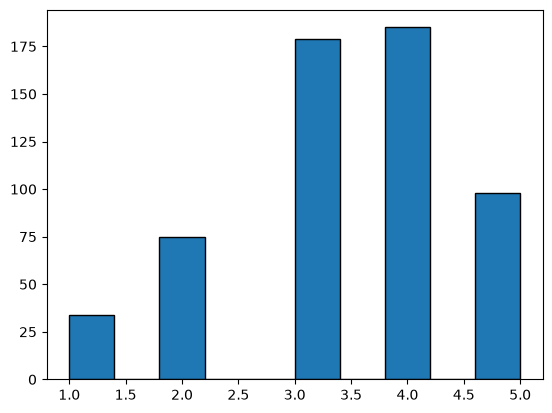

In [118]:
plt.hist(coyote_nature_agreement_responses, edgecolor = "black");

In [45]:
np.max(coyote_nature_agreement_responses)
np.linspace(1,5)

array([1.        , 1.08163265, 1.16326531, 1.24489796, 1.32653061,
       1.40816327, 1.48979592, 1.57142857, 1.65306122, 1.73469388,
       1.81632653, 1.89795918, 1.97959184, 2.06122449, 2.14285714,
       2.2244898 , 2.30612245, 2.3877551 , 2.46938776, 2.55102041,
       2.63265306, 2.71428571, 2.79591837, 2.87755102, 2.95918367,
       3.04081633, 3.12244898, 3.20408163, 3.28571429, 3.36734694,
       3.44897959, 3.53061224, 3.6122449 , 3.69387755, 3.7755102 ,
       3.85714286, 3.93877551, 4.02040816, 4.10204082, 4.18367347,
       4.26530612, 4.34693878, 4.42857143, 4.51020408, 4.59183673,
       4.67346939, 4.75510204, 4.83673469, 4.91836735, 5.        ])

array([0.03226583, 0.03941438, 0.0477329 , 0.05731025, 0.06821786,
       0.08050359, 0.09418543, 0.1092455 , 0.12562461, 0.14321788,
       0.16187176, 0.18138287, 0.20149896, 0.22192216, 0.24231477,
       0.26230734, 0.28150903, 0.29951982, 0.31594402, 0.33040458,
       0.34255737, 0.35210477, 0.35880777, 0.36249592, 0.36307449,
       0.36052857, 0.35492369, 0.34640298, 0.33518116, 0.32153549,
       0.30579443, 0.28832452, 0.26951622, 0.24976961, 0.22948041,
       0.20902728, 0.18876074, 0.16899416, 0.14999718, 0.13199145,
       0.11514892, 0.09959219, 0.08539688, 0.07259557, 0.06118282,
       0.05112111, 0.04234697, 0.0347773 , 0.02831526, 0.02285582])

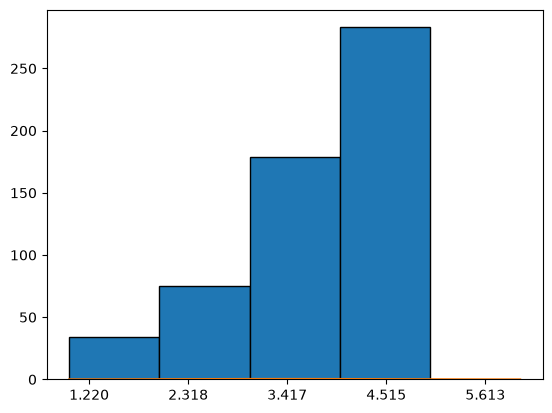

In [119]:
#Normal Distribution
plt.hist(coyote_nature_agreement_responses, bins=np.arange(1.0,6.0), edgecolor = "black")
positions = np.arange(-3, 3.1, 1) * nature_sigma + nature_mu
plt.xticks(positions)
plt.plot(np.linspace(1,6), norm.pdf(np.linspace(1,6),nature_mu,nature_sigma));

norm.pdf(np.linspace(1,6),nature_mu,nature_sigma)
# #use mu, sigma in the equation for normal dist

In [120]:
coyote_nature_agreement_responses.shape

(571,)

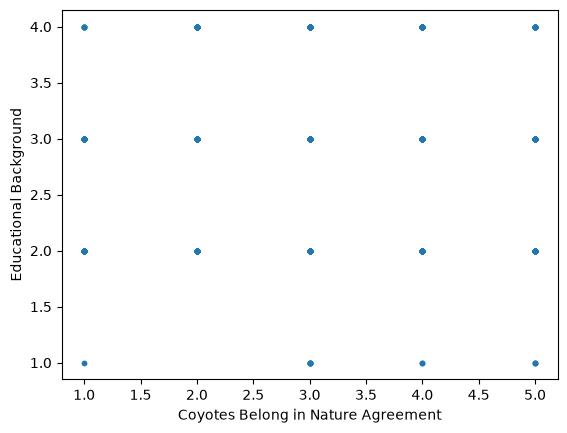

In [121]:
plt.scatter(coyote_nature_agreement_responses, coyote_df['education'], 10)
plt.xlabel('Coyotes Belong in Nature Agreement')
plt.ylabel('Educational Background');

In [140]:
#I need to treat this data differently since Likert scale is catergorical, not going to have useful results with scatterplot for correlation. 
#Histogram was okay, want to see what else I can do

likert_categories = {
    1:"Strongly Disagree", 
    2:"Disagree", 
    3:"Neutral", 
    4:"Agree", 
    5:"Strongly Agree"
}

likert_categories2 = {
    "Strongly Disagree":1, 
    "Disagree":2, 
    "Neutral":3, 
    "Agree":4, 
    "Strongly Agree":5
}

likert_df = coyote_df.apply(lambda x: x.replace(likert_categories))
likert_df.dtypes
display(likert_df)


,Unnamed: 0,learn_live,part_nature,control_pests,afraid_inv,outdoor,sighting_frequency,sighting_nature,education,gender,income,asian,black,race_other,white,county
0,Disagree,Agree,Agree,Agree,Disagree,Agree,Neutral,Strongly Agree,Disagree,Strongly Disagree,Disagree,0,0,0,Strongly Disagree,0
1,Neutral,Neutral,Agree,Agree,Neutral,Neutral,Disagree,Disagree,Neutral,Strongly Disagree,Neutral,0,Strongly Disagree,0,0,0
2,Agree,Strongly Disagree,Strongly Disagree,Strongly Disagree,Agree,Strongly Agree,Neutral,Neutral,Agree,0,Strongly Agree,0,0,0,Strongly Disagree,0
3,Strongly Agree,Neutral,Neutral,Neutral,Neutral,Neutral,0,0,Neutral,Strongly Disagree,Disagree,0,Strongly Disagree,0,0,0
4,7,Disagree,Disagree,Disagree,Neutral,Neutral,Neutral,Neutral,Disagree,Strongly Disagree,Strongly Agree,0,0,0,Strongly Disagree,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
566,603,Disagree,Disagree,Disagree,Agree,Strongly Agree,0,0,Neutral,0,Neutral,0,0,0,Strongly Disagree,Strongly Disagree
567,604,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Disagree,Agree,Neutral,Disagree,Disagree,Strongly Disagree,Disagree,0,0,Strongly Disagree,0,Strongly Disagree
568,605,Agree,Strongly Agree,Neutral,Disagree,Agree,0,0,Neutral,0,Strongly Agree,Strongly Disagree,0,0,0,Strongly Disagree
569,606,Neutral,Neutral,Disagree,Strongly Agree,Neutral,0,0,Neutral,0,Agree,0,0,0,Strongly Disagree,Strongly Disagree


   Unnamed: 0         learn_live        part_nature   control_pests  \
0    Disagree              Agree              Agree           Agree   
6          10  Strongly Disagree  Strongly Disagree        Disagree   
8          12              Agree     Strongly Agree  Strongly Agree   
10         15            Neutral              Agree  Strongly Agree   

           afraid_inv outdoor sighting_frequency    sighting_nature education  \
0            Disagree   Agree            Neutral     Strongly Agree  Disagree   
6   Strongly Disagree   Agree              Agree            Neutral   Neutral   
8   Strongly Disagree   Agree            Neutral           Disagree   Neutral   
10           Disagree   Agree            Neutral  Strongly Disagree   Neutral   

               gender    income asian              black         race_other  \
0   Strongly Disagree  Disagree     0                  0                  0   
6   Strongly Disagree   Neutral     0  Strongly Disagree                  0   
8

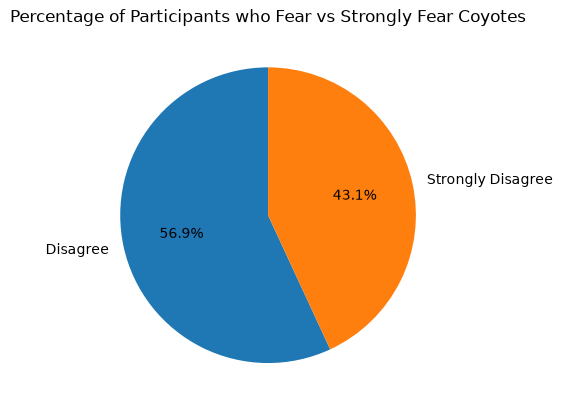

In [150]:

not_afraid_df = likert_df[likert_df["afraid_inv"].str.contains("Disagree|Strongly Disagree")]
print(not_afraid_df.head(4))

not_afraid_df["afraid_inv"].value_counts().plot.pie(autopct="%1.01f%%", startangle=90, ylabel="")
plt.title("Percentage of Participants who Fear vs Strongly Fear Coyotes")
plt.show()

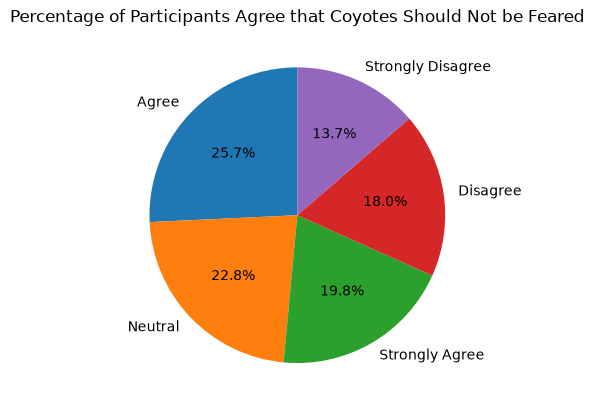

In [143]:
likert_df["afraid_inv"].value_counts().plot.pie(autopct="%1.01f%%", startangle=90, ylabel="")
plt.title("Percentage of Participants Agree that Coyotes Should Not be Feared") #based off of README in dataset the likert scale was reversed for this question, change title accordingly
plt.show()

Text(0.5, 1.0, "Participant Reponses Towards 'We should learn to live with coyotes in my county'")

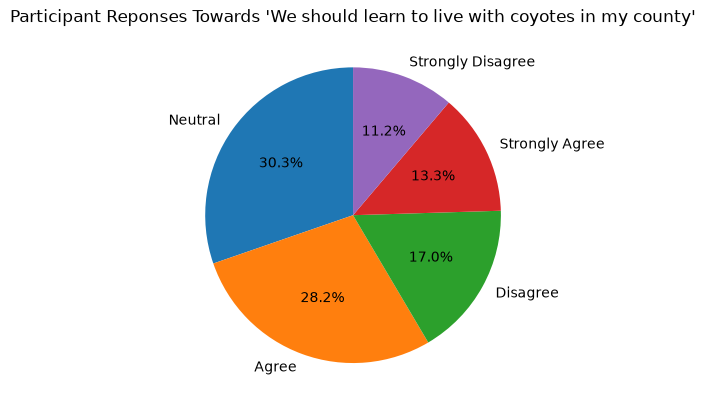

In [148]:
likert_df["learn_live"].value_counts().plot.pie(autopct="%1.01f%%", startangle=90, ylabel="")
plt.title("Participant Reponses Towards 'We should learn to live with coyotes in my county'")


Text(0.5, 1.0, "Participant Reponses Towards 'Coyotes help control populations of pests (e.g. rats, mice) in my county'")

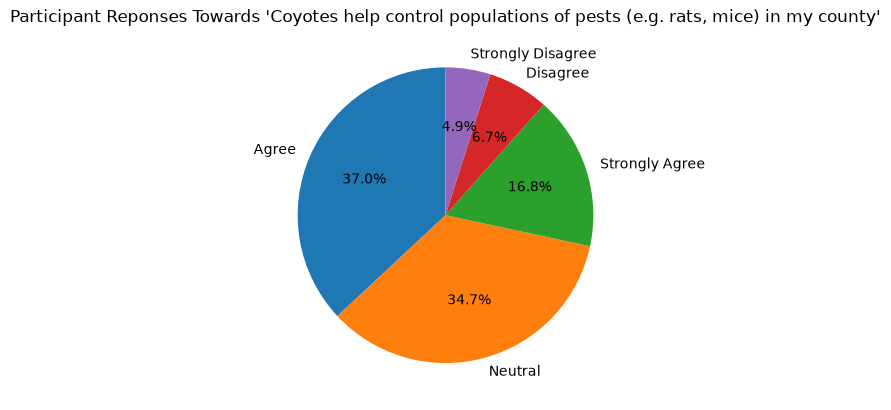

In [149]:
likert_df["control_pests"].value_counts().plot.pie(autopct="%1.01f%%", startangle=90, ylabel="")
plt.title("Participant Reponses Towards 'Coyotes help control populations of pests (e.g. rats, mice) in my county'")


Text(0.5, 1.0, "Participant Reponses Towards 'We should learn to live with coyotes in my county'")

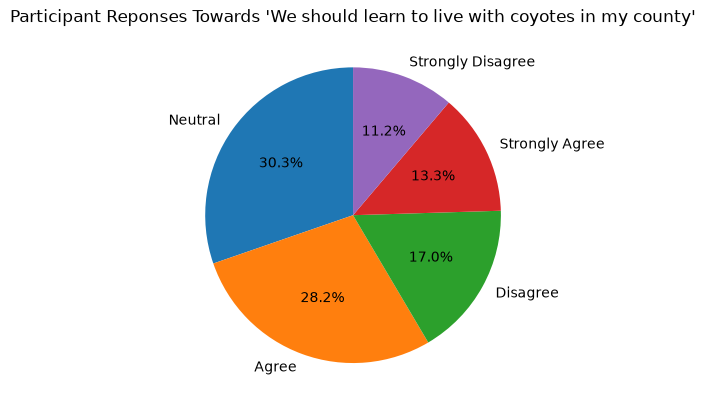

In [151]:
likert_df["learn_live"].value_counts().plot.pie(autopct="%1.01f%%", startangle=90, ylabel="")
plt.title("Participant Reponses Towards 'We should learn to live with coyotes in my county'")
